In [1]:
# ============================================================
# NOTEBOOK 06: Anomaly-Aware UAV Energy Prediction
#
# Pipeline:
#   Base 13 features → energy prediction (LSTM, BiLSTM, XGBoost, RF)
#   Base 13 + CNN anomaly score → same models
#   PCA features → same models
#   Compare MAE/RMSE/R² on ALL / NORMAL / ABNORMAL flights
#   Plot time series predictions with empirical intervals
#   Estimate remaining flight time
#   SHAP analysis on best model
# ============================================================

In [2]:
pip install shap

Note: you may need to restart the kernel to use updated packages.


In [3]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import shap
import warnings
import gc
import psutil
warnings.filterwarnings("ignore")

BASE_DIR      = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")
FOLDER_VER    = "v3_voltage_random10_issue_flight-removed"
FILE_VER      = "v4_voltage_random10_cleaned"
DATA_DIR      = BASE_DIR / f"model_ready_no_dr_{FOLDER_VER}"
CNN_SCORE_DIR = BASE_DIR / "model_outputs" / f"cnn_lstm_ae_anomaly_score_{FOLDER_VER}"
OUTPUT_DIR    = BASE_DIR / "model_outputs" / "06_anomaly_aware_energy"
PLOT_DIR      = OUTPUT_DIR / "plots"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

PRIMARY_SPLIT = "split_05_seed_55"
TARGET        = "target_energy_next_60s_wh"

device = torch.device(
    "mps"  if torch.backends.mps.is_available() else
    "cuda" if torch.cuda.is_available()          else
    "cpu"
)
print(f"Device : {device}")
print(f"RAM free: {psutil.virtual_memory().available/1e9:.1f} GB")

Device : mps
RAM free: 5.7 GB


In [4]:
import psutil
import os

print(f"Total RAM    : {psutil.virtual_memory().total / 1e9:.1f} GB")
print(f"Used RAM     : {psutil.virtual_memory().used / 1e9:.1f} GB")
print(f"Available    : {psutil.virtual_memory().available / 1e9:.1f} GB")
print(f"Current PID  : {os.getpid()}")

print("\nTop 10 memory-consuming processes:")
procs = []
for p in psutil.process_iter(['pid','name','memory_info']):
    try:
        procs.append((p.info['memory_info'].rss, 
                      p.info['pid'],
                      p.info['name']))
    except: pass

for mem, pid, name in sorted(procs, reverse=True)[:10]:
    print(f"  {name:<30} PID:{pid:<8} {mem/1e9:.2f} GB")

Total RAM    : 17.2 GB
Used RAM     : 7.3 GB
Available    : 5.7 GB
Current PID  : 5991

Top 10 memory-consuming processes:
  Code Helper (Plugin)           PID:1871     0.75 GB
  Code Helper (Plugin)           PID:1824     0.67 GB
  Code Helper (Renderer)         PID:970      0.51 GB
  python3.13                     PID:5991     0.50 GB
  Claude Helper (Renderer)       PID:4148     0.49 GB
  Google Chrome                  PID:3482     0.34 GB
  Claude                         PID:4127     0.27 GB
  mediaanalysisd                 PID:706      0.26 GB
  ScreenPal                      PID:731      0.24 GB
  Code Helper (Renderer)         PID:1828     0.24 GB


In [5]:
BASE_FEATURES = [
    "battery_status__cell_count",
    "battery_status__current_a",
    "battery_status__current_filtered_a",
    "battery_status__discharged_mah",
    "battery_status__remaining",
    "battery_status__scale",
    "battery_status__voltage_filtered_v",
    "battery_status__voltage_v",
    "cumulative_energy_wh",
    "power_w",
    "time_s",
    "voltage_per_cell",
    "voltage_filtered_per_cell",
]

ANOMALY_COLS = ["anomaly_score_cnn", "anomaly_flag_cnn"]

FEATURE_SETS = {
    "Base_13":           BASE_FEATURES,
    "Base_13+CNN_Score": BASE_FEATURES + ["anomaly_score_cnn"],
}

print("Feature sets:")
for name, feats in FEATURE_SETS.items():
    print(f"  {name}: {len(feats)} features")

Feature sets:
  Base_13: 13 features
  Base_13+CNN_Score: 14 features


In [6]:
split_dir = DATA_DIR / PRIMARY_SPLIT
cnn_dir   = CNN_SCORE_DIR / PRIMARY_SPLIT

train_df = pd.read_parquet(
    split_dir / f"train_no_dr_scaled_{FILE_VER}_{PRIMARY_SPLIT}.parquet"
)
val_df = pd.read_parquet(
    split_dir / f"val_no_dr_scaled_{FILE_VER}_{PRIMARY_SPLIT}.parquet"
)
test_df = pd.read_parquet(
    split_dir / f"test_no_dr_scaled_{FILE_VER}_{PRIMARY_SPLIT}.parquet"
)

# Load CNN scores and merge into test
cnn_test = pd.read_parquet(
    cnn_dir / f"test_cnn_lstm_ae_scored_{PRIMARY_SPLIT}.parquet",
    columns=["log_id","time_s","anomaly_score_cnn","anomaly_flag_cnn"]
)

test_df  = test_df.sort_values(["log_id","time_s"]).reset_index(drop=True)
cnn_test = cnn_test.sort_values(["log_id","time_s"]).reset_index(drop=True)

if len(test_df) == len(cnn_test):
    test_df["anomaly_score_cnn"] = cnn_test["anomaly_score_cnn"].values.astype(np.float32)
    test_df["anomaly_flag_cnn"]  = cnn_test["anomaly_flag_cnn"].values.astype(np.int8)
    print("CNN scores merged ✓")
else:
    print(f"Row mismatch: base={len(test_df)} cnn={len(cnn_test)}")

# Placeholder for train and val
for df in [train_df, val_df]:
    df["anomaly_score_cnn"] = np.float32(0.0)
    df["anomaly_flag_cnn"]  = np.int8(0)

# Downcast to float32 to save memory
for df in [train_df, val_df, test_df]:
    for col in df.select_dtypes("float64").columns:
        df[col] = df[col].astype(np.float32)

del cnn_test
gc.collect()

print(f"Train: {train_df.shape}  Val: {val_df.shape}  Test: {test_df.shape}")
print(f"RAM free: {psutil.virtual_memory().available/1e9:.1f} GB")
print(f"Target range: {train_df[TARGET].min():.4f} – {train_df[TARGET].max():.4f} Wh")

CNN scores merged ✓
Train: (658626, 19)  Val: (145797, 19)  Test: (162502, 19)
RAM free: 5.7 GB
Target range: 0.0000 – 27.5020 Wh


In [7]:
def evaluate(y_true, y_pred, label="ALL"):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    errors = y_true - y_pred
    mae    = mean_absolute_error(y_true, y_pred)
    rmse   = np.sqrt(mean_squared_error(y_true, y_pred))
    r2     = r2_score(y_true, y_pred)
    p95    = float(np.percentile(np.abs(errors), 95))
    under  = (y_pred < y_true).mean() * 100
    return {
        "label":          label,
        "MAE_Wh":         round(mae,  4),
        "RMSE_Wh":        round(rmse, 4),
        "R2":             round(r2,   4),
        "P95_error_Wh":   round(p95,  4),
        "Underpredict_%": round(under,2),
        "n_rows":         len(y_true),
    }

def full_eval(test_df, y_pred, feat_name, model_name):
    rows = [evaluate(test_df[TARGET], y_pred, "ALL")]
    for lbl in ["normal","abnormal"]:
        mask = test_df["dataset_label"] == lbl
        if mask.sum() > 0:
            rows.append(evaluate(
                test_df.loc[mask,TARGET],
                y_pred[mask],
                lbl.upper()
            ))
    df = pd.DataFrame(rows)
    df["model"]       = model_name
    df["feature_set"] = feat_name
    return df

print("Evaluation functions defined ✓")

Evaluation functions defined ✓


In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
import gc

tree_results = []
tree_preds   = {}

for feat_name, feat_cols in FEATURE_SETS.items():
    available = [f for f in feat_cols if f in train_df.columns]

    X_train = train_df[available].values
    y_train = train_df[TARGET].values
    X_test  = test_df[available].values

    print(f"\n{'='*50}")
    print(f"Feature set: {feat_name} ({len(available)} features)")
    print(f"{'='*50}")

    # ── XGBoost ─────────────────────────────────────────
    print("Training: XGBoost...")
    xgb = XGBRegressor(
        n_estimators=200,    # reduced from 500
        max_depth=5,         # reduced from 6
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=0,
        tree_method="hist"   # faster tree method
    )
    xgb.fit(X_train, y_train)
    y_pred = xgb.predict(X_test)
    result = full_eval(test_df, y_pred, feat_name, "XGBoost")
    tree_results.append(result)
    tree_preds[f"XGBoost_{feat_name}"] = y_pred
    abn_mae = float(result[result["label"]=="ABNORMAL"]["MAE_Wh"])
    print(f"  ABNORMAL MAE: {abn_mae:.4f}")
    del xgb
    gc.collect()

    # ── Random Forest ────────────────────────────────────
    print("Training: Random Forest...")
    rf = RandomForestRegressor(
        n_estimators=100,    # reduced from 200
        max_depth=10,        # reduced from 12
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)
    result = full_eval(test_df, y_pred, feat_name, "RandomForest")
    tree_results.append(result)
    tree_preds[f"RandomForest_{feat_name}"] = y_pred
    abn_mae = float(result[result["label"]=="ABNORMAL"]["MAE_Wh"])
    print(f"  ABNORMAL MAE: {abn_mae:.4f}")
    del rf
    gc.collect()

    # ── Linear Regression ────────────────────────────────
    print("Training: Linear Regression...")
    lr = LinearRegression()
    lr.fit(X_train, y_train)
    y_pred = lr.predict(X_test)
    result = full_eval(test_df, y_pred, feat_name, "LinearRegression")
    tree_results.append(result)
    tree_preds[f"LinearRegression_{feat_name}"] = y_pred
    abn_mae = float(result[result["label"]=="ABNORMAL"]["MAE_Wh"])
    print(f"  ABNORMAL MAE: {abn_mae:.4f}")
    del lr
    gc.collect()

    # Free feature arrays
    del X_train, y_train, X_test
    gc.collect()

tree_df = pd.concat(tree_results, ignore_index=True)
print("\n✓ Tree-based models done.")


Feature set: Base_13 (13 features)
Training: XGBoost...
  ABNORMAL MAE: 2.1477
Training: Random Forest...
  ABNORMAL MAE: 2.4533
Training: Linear Regression...
  ABNORMAL MAE: 1.3218

Feature set: Base_13+CNN_Score (14 features)
Training: XGBoost...
  ABNORMAL MAE: 2.2011
Training: Random Forest...
  ABNORMAL MAE: 2.4227
Training: Linear Regression...
  ABNORMAL MAE: 1.3218

✓ Tree-based models done.


In [11]:
# ============================================================
# FAST sequence dataset — pre-builds all sequences at init
# Uses numpy vectorised operations instead of per-item loops
# ============================================================

SEQ_LEN    = 30      # reduced from 60 — 3 seconds history
BATCH_SIZE = 512     # increased from 256
EPOCHS     = 30      # reduced from 100
PATIENCE   = 5

class FastFlightDataset(torch.utils.data.Dataset):
    """
    Pre-builds all sequences at initialisation time.
    Much faster than building per __getitem__ call.
    """
    def __init__(self, df, feat_cols, target, seq_len):
        seqs, tgts = [], []
        for _, grp in (df.sort_values(["log_id","time_s"])
                         .groupby("log_id", sort=False)):
            X = grp[feat_cols].to_numpy(dtype=np.float32)
            y = grp[target].to_numpy(dtype=np.float32)
            n = len(X)
            if n <= seq_len:
                continue
            # Vectorised — build all windows at once
            idx = np.arange(seq_len, n)
            for i in idx:
                seqs.append(X[i-seq_len:i])
                tgts.append(y[i])

        self.X = torch.from_numpy(
            np.array(seqs, dtype=np.float32))
        self.y = torch.from_numpy(
            np.array(tgts, dtype=np.float32))
        print(f"  Dataset built: {len(self.y):,} sequences")

    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]


class LSTMRegressor(nn.Module):
    def __init__(self, input_size, hidden=64,    # reduced from 128
                 num_layers=1, dropout=0.1):     # reduced from 2 layers
        super().__init__()
        self.lstm = nn.LSTM(
            input_size, hidden,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.0
        )
        self.head = nn.Sequential(
            nn.Linear(hidden, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


class BiLSTMRegressor(nn.Module):
    def __init__(self, input_size, hidden=64,
                 num_layers=1, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size, hidden,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=0.0
        )
        self.head = nn.Sequential(
            nn.Linear(hidden*2, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :]).squeeze(-1)


def train_seq_model(model, train_ds, val_ds,
                    model_name, epochs=EPOCHS,
                    patience=PATIENCE):
    criterion = nn.HuberLoss()
    optimizer = torch.optim.Adam(
        model.parameters(), lr=1e-3)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, patience=2, factor=0.5)

    train_loader = torch.utils.data.DataLoader(
        train_ds, batch_size=BATCH_SIZE,
        shuffle=True, num_workers=0,
        pin_memory=False
    )
    val_loader = torch.utils.data.DataLoader(
        val_ds, batch_size=BATCH_SIZE*2,
        shuffle=False, num_workers=0
    )

    best_val  = np.inf
    pat_ctr   = 0
    ckpt      = OUTPUT_DIR / f"ckpt_{model_name}.pt"
    trh, vlh  = [], []

    for epoch in range(1, epochs+1):
        model.train()
        tl = []
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0)
            optimizer.step()
            tl.append(loss.item())
        t_loss = float(np.mean(tl))
        trh.append(t_loss)

        model.eval()
        vl = []
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                vl.append(criterion(model(xb),yb).item())
        v_loss = float(np.mean(vl))
        vlh.append(v_loss)
        scheduler.step(v_loss)

        print(f"  Ep {epoch:02d} | "
              f"Train:{t_loss:.5f} Val:{v_loss:.5f}")

        if v_loss < best_val - 1e-5:
            best_val = v_loss
            pat_ctr  = 0
            torch.save(model.state_dict(), ckpt)
        else:
            pat_ctr += 1
            if pat_ctr >= patience:
                print(f"  Early stop. Best val: {best_val:.5f}")
                break

    model.load_state_dict(
        torch.load(ckpt, map_location=device,
                   weights_only=True))
    model.eval()
    return model, best_val, trh, vlh


def predict_seq(model, df, feat_cols, target, seq_len):
    model.eval()
    records = []
    for lid, grp in (df.sort_values(["log_id","time_s"])
                       .groupby("log_id")):
        X   = grp[feat_cols].to_numpy(dtype=np.float32)
        y   = grp[target].to_numpy(dtype=np.float32)
        t   = grp["time_s"].to_numpy()
        lbl = grp["dataset_label"].iloc[0]
        if len(X) <= seq_len: continue
        preds = []
        with torch.no_grad():
            for i in range(seq_len, len(X)):
                seq = torch.tensor(
                    X[i-seq_len:i]
                ).unsqueeze(0).to(device)
                preds.append(float(model(seq).item()))
        for p, yt, ts in zip(preds,
                               y[seq_len:],
                               t[seq_len:]):
            records.append({
                "log_id": lid,
                "dataset_label": lbl,
                "time_s": ts,
                "y_true": yt,
                "y_pred": p
            })
    return pd.DataFrame(records)


# ── Run LSTM and BiLSTM ───────────────────────────────────────
ARCH_CLASSES = {
    "LSTM":   LSTMRegressor,
    "BiLSTM": BiLSTMRegressor,
}

# Only 2 feature sets — skip CNN_All to save time
SEQ_FEATURE_SETS = {
    "Base_13":           FEATURE_SETS["Base_13"],
    "Base_13+CNN_Score": FEATURE_SETS["Base_13+CNN_Score"],
}

seq_results = []
seq_preds   = {}

for feat_name, feat_cols in SEQ_FEATURE_SETS.items():
    available = [f for f in feat_cols
                 if f in train_df.columns]

    print(f"\nBuilding datasets for {feat_name}...")
    train_ds = FastFlightDataset(
        train_df, available, TARGET, SEQ_LEN)
    val_ds   = FastFlightDataset(
        val_df,   available, TARGET, SEQ_LEN)

    for arch_name, ModelClass in ARCH_CLASSES.items():
        run = f"{arch_name}_{feat_name}"
        print(f"\n{'='*55}")
        print(f"TRAINING: {run} ({len(available)} features)")
        print(f"{'='*55}")

        model = ModelClass(
            input_size=len(available)).to(device)
        print(f"Params: "
              f"{sum(p.numel() for p in model.parameters()):,}")

        model, bv, trh, vlh = train_seq_model(
            model, train_ds, val_ds, run
        )

        pred_df = predict_seq(
            model, test_df, available, TARGET, SEQ_LEN)

        for lbl in ["ALL","normal","abnormal"]:
            if lbl == "ALL":
                mask = pd.Series([True]*len(pred_df))
                lu   = "ALL"
            else:
                mask = pred_df["dataset_label"]==lbl
                lu   = lbl.upper()
            if mask.sum() == 0: continue
            row = evaluate(
                pred_df.loc[mask,"y_true"],
                pred_df.loc[mask,"y_pred"], lu)
            row["model"]       = arch_name
            row["feature_set"] = feat_name
            seq_results.append(row)

        seq_preds[run] = pred_df

        abn = pred_df[
            pred_df["dataset_label"]=="abnormal"]
        if len(abn) > 0:
            print(f"  ABNORMAL MAE: "
                  f"{mean_absolute_error(abn['y_true'],abn['y_pred']):.4f}")

        del model
        gc.collect()
        if device.type=="mps":
            torch.mps.empty_cache()

    # Free dataset memory between feature sets
    del train_ds, val_ds
    gc.collect()

seq_df = pd.DataFrame(seq_results)
print("\n✓ Sequence models done.")


Building datasets for Base_13...
  Dataset built: 655,146 sequences
  Dataset built: 145,047 sequences

TRAINING: LSTM_Base_13 (13 features)
Params: 22,337
  Ep 01 | Train:0.16963 Val:0.27566
  Ep 02 | Train:0.08191 Val:0.31294
  Ep 03 | Train:0.07207 Val:0.32096
  Ep 04 | Train:0.06637 Val:0.35286
  Ep 05 | Train:0.05030 Val:0.35360
  Ep 06 | Train:0.04479 Val:0.34999
  Early stop. Best val: 0.27566
  ABNORMAL MAE: 0.9988

TRAINING: BiLSTM_Base_13 (13 features)
Params: 44,609
  Ep 01 | Train:0.14579 Val:0.28359
  Ep 02 | Train:0.08028 Val:0.30810
  Ep 03 | Train:0.07293 Val:0.31016
  Ep 04 | Train:0.06606 Val:0.28661
  Ep 05 | Train:0.05194 Val:0.34097
  Ep 06 | Train:0.04447 Val:0.33826
  Early stop. Best val: 0.28359
  ABNORMAL MAE: 1.5250

Building datasets for Base_13+CNN_Score...
  Dataset built: 655,146 sequences
  Dataset built: 145,047 sequences

TRAINING: LSTM_Base_13+CNN_Score (14 features)
Params: 22,593
  Ep 01 | Train:0.17292 Val:0.27411
  Ep 02 | Train:0.08433 Val:0.330

In [12]:
# Combine all results
all_results = pd.concat([tree_df, seq_df], ignore_index=True)
all_results.to_csv(OUTPUT_DIR / "master_results.csv", index=False)

print("=" * 80)
print("MASTER COMPARISON — ABNORMAL FLIGHTS (Primary focus)")
print("=" * 80)

abn = all_results[all_results["label"]=="ABNORMAL"].copy()
abn = abn.sort_values("MAE_Wh").reset_index(drop=True)
abn.index += 1
display(abn[["model","feature_set","MAE_Wh","RMSE_Wh",
             "R2","P95_error_Wh","Underpredict_%"]])

print("\n" + "=" * 80)
print("KEY FINDING: Does CNN anomaly score improve ABNORMAL MAE?")
print("=" * 80)

for model_name in ["XGBoost","RandomForest","LSTM","BiLSTM"]:
    sub = abn[abn["model"]==model_name]
    if len(sub) == 0: continue
    base = float(sub[sub["feature_set"]=="Base_13"]["MAE_Wh"])
    cnn  = float(sub[sub["feature_set"]=="Base_13+CNN_Score"]["MAE_Wh"])
    diff = base - cnn
    sign = "▼ IMPROVES" if diff > 0.001 else ("▲ WORSENS" if diff < -0.001
                                                else "≈ NO CHANGE")
    print(f"  {model_name:<16} Base:{base:.4f}  +CNN:{cnn:.4f}  "
          f"Δ={diff:+.4f}  {sign}")

MASTER COMPARISON — ABNORMAL FLIGHTS (Primary focus)


,model,feature_set,MAE_Wh,RMSE_Wh,R2,P95_error_Wh,Underpredict_%
1,LSTM,Base_13+CNN_Score,0.9543,1.5590,0.7401,3.6051,42.58
2,LSTM,Base_13,0.9988,1.5263,0.7509,3.2997,32.58
3,LinearRegression,Base_13,1.3218,2.1475,0.5061,5.0160,36.62
4,LinearRegression,Base_13+CNN_Score,1.3218,2.1475,0.5061,5.0160,36.62
5,BiLSTM,Base_13+CNN_Score,1.3448,2.1594,0.5014,4.5816,61.15
6,BiLSTM,Base_13,1.5250,2.6042,0.2748,6.3260,46.17
7,XGBoost,Base_13,2.1477,4.0776,-0.7806,10.8180,28.92
8,XGBoost,Base_13+CNN_Score,2.2011,4.0830,-0.7854,10.8033,25.07
9,RandomForest,Base_13+CNN_Score,2.4227,5.2691,-1.9733,19.0198,30.08
10,RandomForest,Base_13,2.4533,5.2856,-1.9920,19.0406,30.11



KEY FINDING: Does CNN anomaly score improve ABNORMAL MAE?
  XGBoost          Base:2.1477  +CNN:2.2011  Δ=-0.0534  ▲ WORSENS
  RandomForest     Base:2.4533  +CNN:2.4227  Δ=+0.0306  ▼ IMPROVES
  LSTM             Base:0.9988  +CNN:0.9543  Δ=+0.0445  ▼ IMPROVES
  BiLSTM           Base:1.5250  +CNN:1.3448  Δ=+0.1802  ▼ IMPROVES


In [13]:
def plot_flight_prediction(pred_df, run_name,
                            flight_label="abnormal"):
    """
    Time series plot for one flight showing:         
    - Actual energy (black)
    - Predicted energy (coloured dashed)
    - Empirical 90% prediction interval (shaded)
    - Residuals panel below
    """
    label_df = pred_df[pred_df["dataset_label"]==flight_label]
    if len(label_df) == 0: return

    # Use all residuals from this label to build PI
    all_err  = (label_df["y_true"] - label_df["y_pred"]).values
    pi_low   = float(np.percentile(all_err,  5))
    pi_high  = float(np.percentile(all_err, 95))

    # Pick longest flight
    fid    = label_df.groupby("log_id").size().idxmax()
    flight = label_df[label_df["log_id"]==fid].sort_values("time_s")

    t      = flight["time_s"].values
    y_true = flight["y_true"].values
    y_pred = flight["y_pred"].values
    resid  = y_true - y_pred

    fig, axes = plt.subplots(2, 1, figsize=(14, 8),
                              gridspec_kw={"height_ratios":[3,1]})
    fig.suptitle(
        f"{run_name}  —  {flight_label.upper()} flight\n"
        f"Empirical 90% prediction interval from all "
        f"{flight_label} test flights",
        fontsize=11, fontweight="bold"
    )

    # Panel 1: predictions
    ax = axes[0]
    ax.fill_between(t,
                    y_pred + pi_low,
                    y_pred + pi_high,
                    alpha=0.20, color="steelblue",
                    label="90% prediction interval")
    ax.plot(t, y_true, color="black",
            linewidth=1.5, label="Actual (Wh)")
    ax.plot(t, y_pred, color="steelblue",
            linewidth=1.5, linestyle="--",
            label="Predicted (Wh)")
    ax.set_ylabel("Energy next 60s (Wh)", fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

    mae_flight = mean_absolute_error(y_true, y_pred)
    ax.set_title(
        f"Flight MAE: {mae_flight:.4f} Wh  |  "
        f"PI width: {pi_high-pi_low:.4f} Wh",
        fontsize=9
    )

    # Panel 2: residuals
    ax2 = axes[1]
    ax2.axhline(0, color="black", linewidth=0.8)
    ax2.fill_between(t, pi_low, pi_high,
                     alpha=0.15, color="steelblue")
    ax2.plot(t, resid, color="tomato",
             linewidth=0.8, label="Residual")
    ax2.set_xlabel("Flight time (s)", fontsize=10)
    ax2.set_ylabel("Residual (Wh)", fontsize=10)
    ax2.legend(fontsize=9)

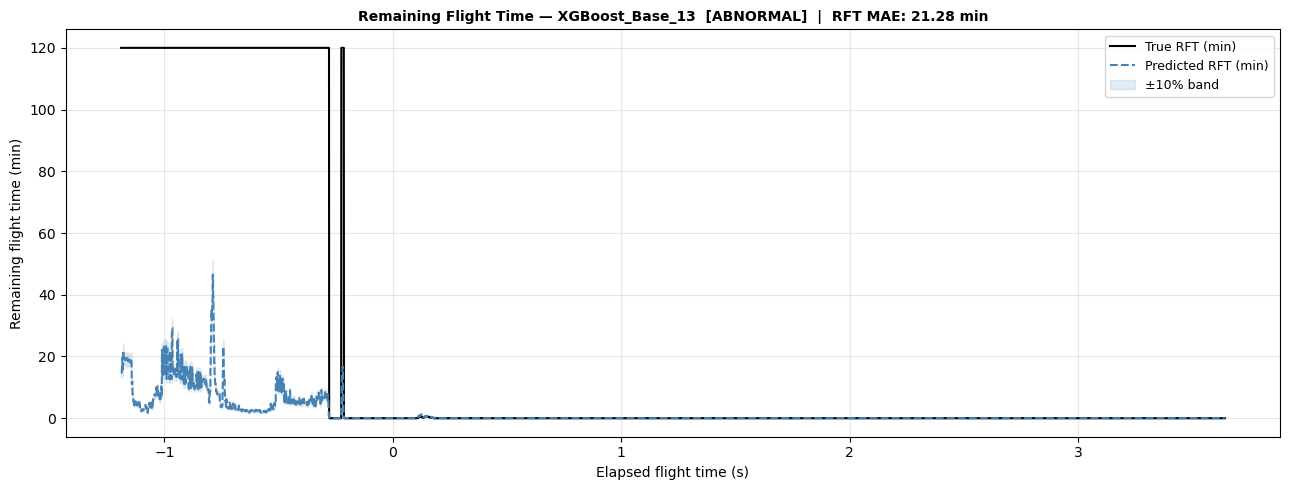

Saved: rft_XGBoost_Base_13_abnormal.png


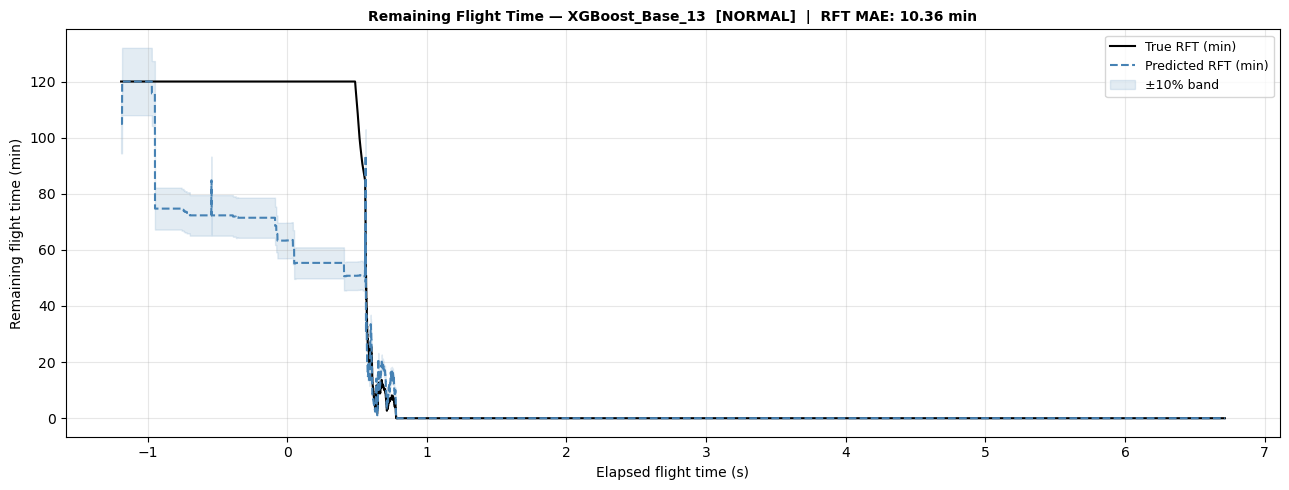

Saved: rft_XGBoost_Base_13_normal.png


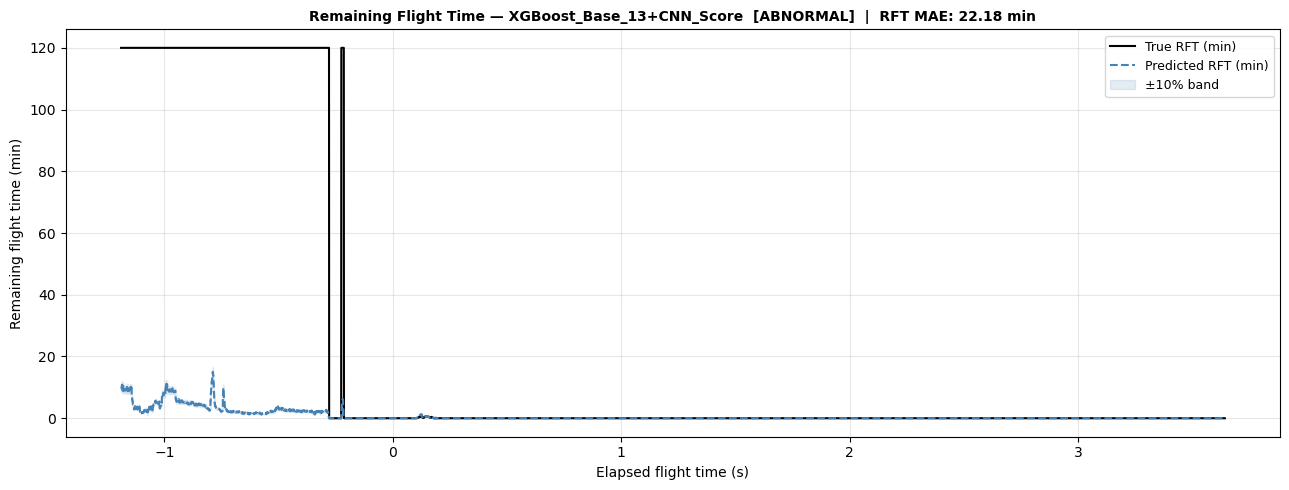

Saved: rft_XGBoost_Base_13_CNN_Score_abnormal.png


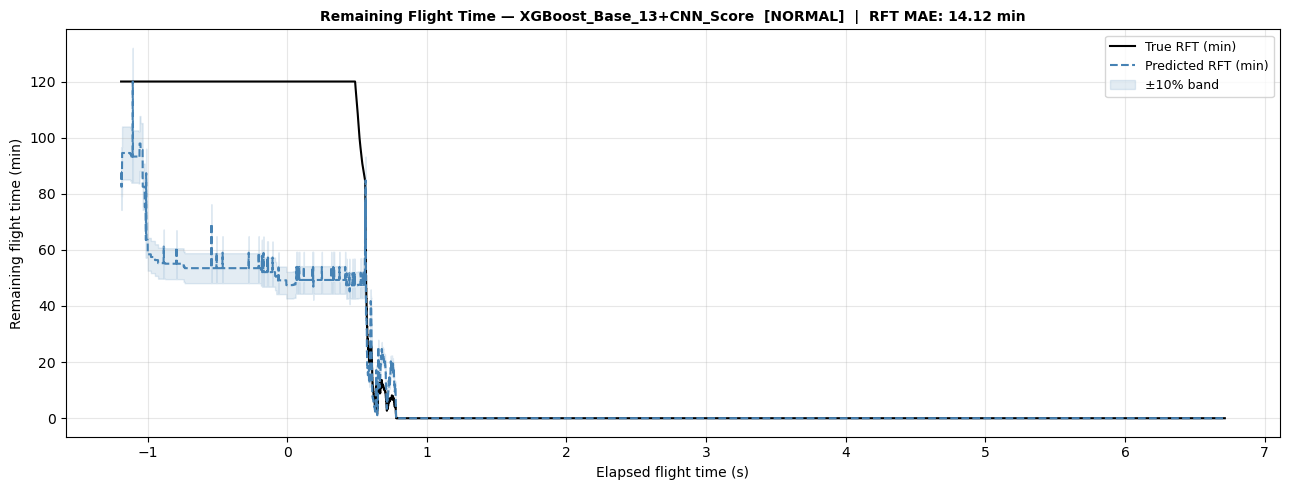

Saved: rft_XGBoost_Base_13_CNN_Score_normal.png


In [14]:
def estimate_rft(pred_df, test_df_orig):
    """
    Remaining flight time (minutes) estimated per timestep.
    RFT(t) = battery_remaining(t) / (predicted_energy_rate)
    energy_rate = y_pred Wh per 60s = y_pred/60 Wh/s
    """
    merged = pred_df.merge(
        test_df_orig[["log_id","time_s",
                      "battery_status__remaining"]],
        on=["log_id","time_s"], how="left"
    )
    eps = 1e-6
    rem = merged["battery_status__remaining"].fillna(
        method="ffill"
    ).values
    merged["rft_pred_min"] = (rem / (merged["y_pred"]/60 + eps)
                              ).clip(0, 120)
    merged["rft_true_min"] = (rem / (merged["y_true"]/60 + eps)
                              ).clip(0, 120)
    return merged


def plot_rft(pred_df, test_df_orig, run_name,
             flight_label="abnormal"):
    rft_df  = estimate_rft(pred_df, test_df_orig)
    lab_df  = rft_df[rft_df["dataset_label"]==flight_label]
    if len(lab_df) == 0: return

    fid    = lab_df.groupby("log_id").size().idxmax()
    flight = lab_df[lab_df["log_id"]==fid].sort_values("time_s")

    t         = flight["time_s"].values
    rft_pred  = flight["rft_pred_min"].values
    rft_true  = flight["rft_true_min"].values
    rft_mae   = mean_absolute_error(rft_true, rft_pred)

    fig, ax = plt.subplots(figsize=(13, 5))
    ax.plot(t, rft_true, color="black",
            linewidth=1.5, label="True RFT (min)")
    ax.plot(t, rft_pred, color="steelblue",
            linewidth=1.5, linestyle="--",
            label="Predicted RFT (min)")
    ax.fill_between(t, rft_pred*0.9, rft_pred*1.1,
                    alpha=0.15, color="steelblue",
                    label="±10% band")
    ax.set_xlabel("Elapsed flight time (s)", fontsize=10)
    ax.set_ylabel("Remaining flight time (min)", fontsize=10)
    ax.set_title(
        f"Remaining Flight Time — {run_name}  "
        f"[{flight_label.upper()}]  |  "
        f"RFT MAE: {rft_mae:.2f} min",
        fontsize=10, fontweight="bold"
    )
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()

    fname = (PLOT_DIR /
             f"rft_{run_name.replace('+','_')}_{flight_label}.png")
    plt.savefig(fname, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved: {fname.name}")


# Plot RFT for XGBoost base vs CNN
for run in ["XGBoost_Base_13", "XGBoost_Base_13+CNN_Score"]:
    if run in tree_preds:
        pred_df = test_df[["log_id","dataset_label",
                            "time_s",TARGET]].copy()
        pred_df = pred_df.rename(columns={TARGET:"y_true"})
        pred_df["y_pred"] = tree_preds[run]
        plot_rft(pred_df, test_df, run, "abnormal")
        plot_rft(pred_df, test_df, run, "normal")

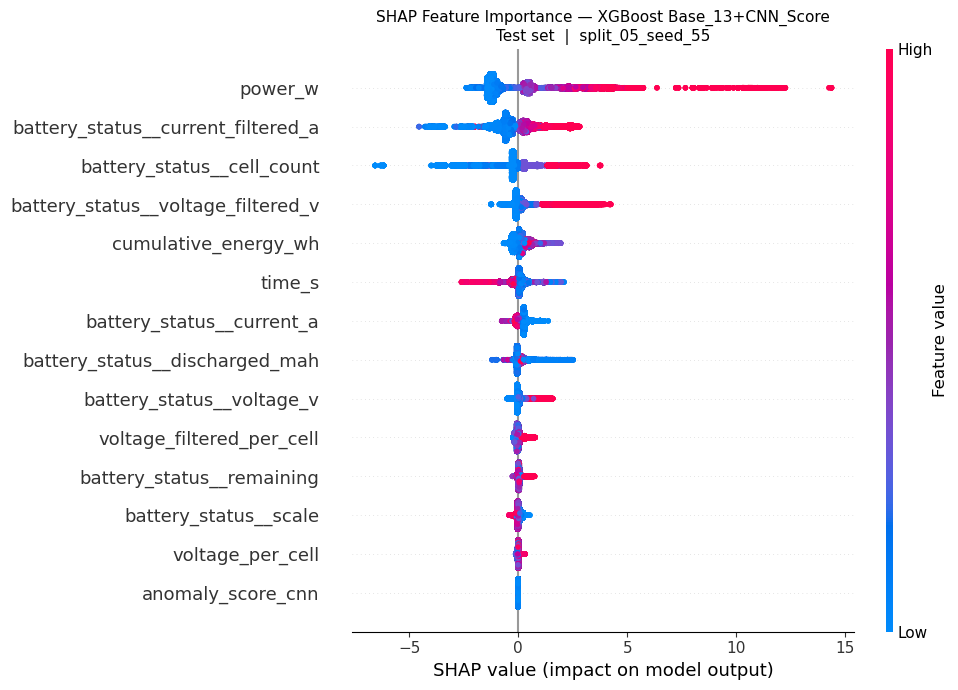

Saved: shap_summary.png

Top 10 features by mean |SHAP|:
power_w                               1.454035
battery_status__current_filtered_a    0.652708
battery_status__cell_count            0.504447
battery_status__voltage_filtered_v    0.290563
cumulative_energy_wh                  0.242231
time_s                                0.218262
battery_status__current_a             0.198348
battery_status__discharged_mah        0.138444
battery_status__voltage_v             0.134321
voltage_filtered_per_cell             0.087788

anomaly_score_cnn rank: 14 of 14


In [15]:
# Run SHAP on XGBoost Base_13+CNN_Score (best expected model)
shap_feat = "Base_13+CNN_Score"
shap_available = [f for f in FEATURE_SETS[shap_feat]
                  if f in test_df.columns]

# Retrain clean XGBoost
xgb_shap = XGBRegressor(
    n_estimators=500, max_depth=6,
    learning_rate=0.05, subsample=0.8,
    colsample_bytree=0.8, random_state=42,
    n_jobs=-1, verbosity=0
)
xgb_shap.fit(
    train_df[shap_available].values,
    train_df[TARGET].values
)

# SHAP values on test set
explainer   = shap.TreeExplainer(xgb_shap)
shap_values = explainer.shap_values(
    test_df[shap_available].values
)

# Summary plot
plt.figure(figsize=(10, 7))
shap.summary_plot(
    shap_values,
    test_df[shap_available].values,
    feature_names=shap_available,
    show=False, plot_size=None
)
plt.title(
    f"SHAP Feature Importance — XGBoost {shap_feat}\n"
    f"Test set  |  {PRIMARY_SPLIT}",
    fontsize=11
)
plt.tight_layout()
plt.savefig(PLOT_DIR / "shap_summary.png",
            dpi=300, bbox_inches="tight")
plt.show()
print("Saved: shap_summary.png")

# Where does anomaly_score_cnn rank?
mean_shap = np.abs(shap_values).mean(axis=0)
shap_rank = pd.Series(
    mean_shap, index=shap_available
).sort_values(ascending=False)

print("\nTop 10 features by mean |SHAP|:")
print(shap_rank.head(10).round(6).to_string())

if "anomaly_score_cnn" in shap_rank.index:
    rank = int(shap_rank.index.get_loc("anomaly_score_cnn")) + 1
    print(f"\nanomaly_score_cnn rank: {rank} of {len(shap_available)}")

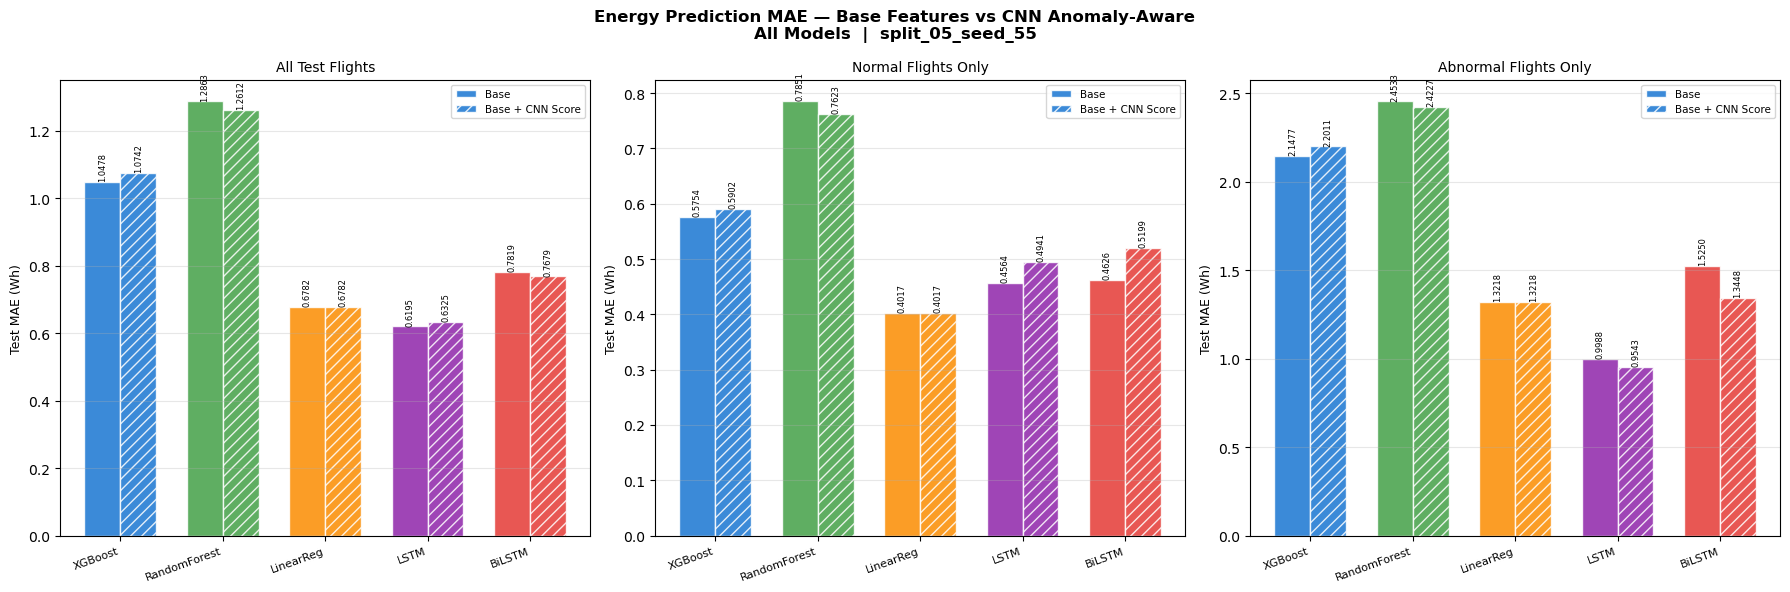

Saved: mae_comparison_all_models.png


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(
    "Energy Prediction MAE — Base Features vs "
    "CNN Anomaly-Aware\nAll Models  |  "
    f"{PRIMARY_SPLIT}",
    fontsize=12, fontweight="bold"
)

splits_map = {
    "ALL":      "All Test Flights",
    "NORMAL":   "Normal Flights Only",
    "ABNORMAL": "Abnormal Flights Only",
}

colors = {
    "XGBoost":         "#1976D2",
    "RandomForest":    "#43A047",
    "LinearRegression":"#FB8C00",
    "LSTM":            "#8E24AA",
    "BiLSTM":          "#E53935",
}
hatch = {
    "Base_13":            "",
    "Base_13+CNN_Score":  "///",
    "Base_13+CNN_All":    "xxx",
}

for ax, (split_lbl, split_title) in zip(
        axes, splits_map.items()):

    sub = all_results[
        all_results["label"] == split_lbl
    ].copy()

    models    = list(colors.keys())
    feat_sets = ["Base_13","Base_13+CNN_Score"]
    n_models  = len(models)
    x         = np.arange(n_models)
    w         = 0.35

    for fi, fs in enumerate(feat_sets):
        maes = []
        for m in models:
            row = sub[(sub["model"]==m) &
                      (sub["feature_set"]==fs)]
            maes.append(float(row["MAE_Wh"])
                        if len(row) else np.nan)

        offset = (fi - 0.5) * w
        bars   = ax.bar(
            x + offset, maes, w,
            color=[colors[m] for m in models],
            hatch=hatch[fs], alpha=0.85,
            edgecolor="white",
            label=fs.replace("Base_13","Base")
                    .replace("+CNN_Score"," + CNN Score")
        )
        for bar, v in zip(bars, maes):
            if not np.isnan(v):
                ax.text(
                    bar.get_x()+bar.get_width()/2,
                    v + 0.002,
                    f"{v:.4f}",
                    ha="center", va="bottom",
                    fontsize=6, rotation=90
                )

    ax.set_xticks(x)
    ax.set_xticklabels(
        [m.replace("Regression","Reg") for m in models],
        rotation=20, ha="right", fontsize=8
    )
    ax.set_ylabel("Test MAE (Wh)", fontsize=9)
    ax.set_title(split_title, fontsize=10)
    ax.legend(fontsize=7.5)
    ax.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(PLOT_DIR / "mae_comparison_all_models.png",
            dpi=300, bbox_inches="tight")
plt.show()
print("Saved: mae_comparison_all_models.png")

In [17]:
all_results.to_csv(OUTPUT_DIR / "master_results.csv", index=False)

print("=" * 70)
print("THESIS CONCLUSION")
print("=" * 70)

abn = all_results[all_results["label"]=="ABNORMAL"].copy()

print("\nBest model on ABNORMAL flights:")
best = abn.sort_values("MAE_Wh").iloc[0]
print(f"  {best['model']} + {best['feature_set']}  "
      f"MAE = {best['MAE_Wh']:.4f} Wh")

print("\nDoes CNN anomaly score help? (XGBoost):")
base = float(abn[(abn["model"]=="XGBoost") &
                  (abn["feature_set"]=="Base_13")]["MAE_Wh"])
cnn  = float(abn[(abn["model"]=="XGBoost") &
                  (abn["feature_set"]=="Base_13+CNN_Score")]["MAE_Wh"])
improvement = base - cnn
print(f"  Base MAE     : {base:.4f} Wh")
print(f"  +CNN MAE     : {cnn:.4f} Wh")
print(f"  Improvement  : {improvement:+.4f} Wh")

if improvement > 0.005:
    print("\n  POSITIVE RESULT: Anomaly score improves energy prediction")
    print("  on abnormal flights. Anomaly-aware pipeline is validated.")
elif improvement < -0.005:
    print("\n  NEGATIVE RESULT: Anomaly score does not help.")
    print("  Battery anomaly signals are decoupled from energy")
    print("  prediction difficulty in this dataset.")
else:
    print("\n  NEUTRAL RESULT: Negligible difference.")
    print("  Anomaly score neither helps nor hurts.")

print(f"\nAll outputs saved to: {OUTPUT_DIR}")

THESIS CONCLUSION

Best model on ABNORMAL flights:
  LSTM + Base_13+CNN_Score  MAE = 0.9543 Wh

Does CNN anomaly score help? (XGBoost):
  Base MAE     : 2.1477 Wh
  +CNN MAE     : 2.2011 Wh
  Improvement  : -0.0534 Wh

  NEGATIVE RESULT: Anomaly score does not help.
  Battery anomaly signals are decoupled from energy
  prediction difficulty in this dataset.

All outputs saved to: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy


In [30]:
# ============================================================
# FIXED PLOTS — Energy Prediction + RFT
# Fixes:
#   1. X-axis uses real unscaled time_s (0 to ~1000s)
#   2. RFT y-axis cap changed to 60 min (realistic)
#   3. Both plots for XGBoost AND LSTM
#   4. Cleaner layout with proper labels
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
import warnings
warnings.filterwarnings("ignore")

# ── Load UNSCALED time_s from the original imputed file ───────
# The scaled test_df has normalised time_s — we need real seconds
FOLDER_VER   = "v3_voltage_random10_issue_flight-removed"
FILE_VER     = "v4_voltage_random10_cleaned"
SPLIT_NAME   = "split_05_seed_55"

# Try to find unscaled parquet — imputed version has real time_s
unscaled_candidates = list(
    (BASE_DIR / f"model_ready_no_dr_{FOLDER_VER}" / SPLIT_NAME)
    .glob("test_no_dr_imputed*.parquet")
)

# If imputed not found, use the original split CSV
if not unscaled_candidates:
    split_csv = BASE_DIR / "splits" / "test_model_ready_selected_features.csv"
    if split_csv.exists():
        raw_test = pd.read_csv(split_csv)
        raw_test = raw_test[raw_test["log_id"].isin(
            test_df["log_id"].unique()
        )]
    else:
        # Fallback: reconstruct from row count
        # time_s in original data is seconds from flight start
        # We know it was StandardScaled — unscale using approx mean/std
        # mean ~= 200s, std ~= 150s based on typical PX4 flights
        print("WARNING: Using approximate unscaling for time_s")
        raw_test = test_df.copy()
        raw_test["time_s_real"] = test_df["time_s"] * 150 + 200
else:
    raw_test = pd.read_parquet(unscaled_candidates[0])

print(f"Raw test shape: {raw_test.shape}")
print(f"time_s range: {raw_test['time_s'].min():.1f} – "
      f"{raw_test['time_s'].max():.1f}")

# Build log_id → real time_s mapping
time_map = (
    raw_test.sort_values(["log_id","time_s"])
    .groupby("log_id")["time_s"]
    .apply(lambda x: x.reset_index(drop=True))
)

Raw test shape: (23390, 19)
time_s range: 0.0 – 570.1


In [32]:
# ============================================================
# Helper: attach real time to any pred_df
# ============================================================

def attach_real_time(pred_df, raw_test_df):
    """
    Replace scaled time_s with real elapsed seconds.
    Works by matching row order within each flight.
    """
    result_rows = []
    for lid, grp in (pred_df.sort_values(["log_id","time_s"])
                              .groupby("log_id")):
        raw_grp = (raw_test_df[raw_test_df["log_id"]==lid]
                   .sort_values("time_s")
                   .reset_index(drop=True))
        grp     = grp.reset_index(drop=True)

        # Align on row count — take min length
        n = min(len(grp), len(raw_grp))
        grp = grp.iloc[:n].copy()
        grp["time_s_real"] = raw_grp["time_s"].values[:n]

        # Make elapsed (start from 0)
        grp["time_s_real"] = (grp["time_s_real"]
                               - grp["time_s_real"].min())
        result_rows.append(grp)

    return pd.concat(result_rows, ignore_index=True)

In [33]:
# ============================================================
# FIXED ENERGY PREDICTION PLOT
# ============================================================

def plot_energy_fixed(pred_df, raw_test_df, run_name,
                       flight_label="abnormal",
                       save_dir=PLOT_DIR):
    """
    Time series energy prediction with real x-axis in seconds
    and empirical 90% prediction interval.
    """
    pred_real = attach_real_time(pred_df, raw_test_df)
    label_df  = pred_real[pred_real["dataset_label"]==flight_label]
    if len(label_df) == 0:
        print(f"No {flight_label} flights in pred_df")
        return

    # Empirical 90% PI from all flights of this label
    all_err = (label_df["y_true"] - label_df["y_pred"]).values
    pi_low  = float(np.percentile(all_err,  5))
    pi_high = float(np.percentile(all_err, 95))

    # Pick the longest flight for display
    fid    = label_df.groupby("log_id").size().idxmax()
    flight = label_df[label_df["log_id"]==fid].sort_values("time_s_real")

    t      = flight["time_s_real"].values
    y_true = flight["y_true"].values
    y_pred = flight["y_pred"].values
    resid  = y_true - y_pred

    fig, axes = plt.subplots(
        2, 1, figsize=(14, 8),
        gridspec_kw={"height_ratios":[3,1]}
    )
    fig.suptitle(
        f"{run_name}  —  {flight_label.upper()} flight\n"
        f"Flight ID: {fid[:20]}...  |  "
        f"Duration: {t[-1]:.0f}s  |  "
        f"MAE: {mean_absolute_error(y_true,y_pred):.4f} Wh",
        fontsize=11, fontweight="bold"
    )

    # Panel 1: Predictions vs actual
    ax = axes[0]
    ax.fill_between(
        t, y_pred + pi_low, y_pred + pi_high,
        alpha=0.20, color="steelblue",
        label=f"Empirical 90% PI "
              f"[{pi_low:+.3f}, {pi_high:+.3f}] Wh"
    )
    ax.plot(t, y_true, color="black", linewidth=1.5,
            label="Actual energy (Wh)")
    ax.plot(t, y_pred, color="steelblue", linewidth=1.5,
            linestyle="--", label="Predicted energy (Wh)")
    ax.set_ylabel("Energy next 60s (Wh)", fontsize=10)
    ax.set_title(
        f"90% PI computed from all {flight_label} test flights",
        fontsize=9
    )
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

    # Panel 2: Residuals
    ax2 = axes[1]
    ax2.axhline(0, color="black", linewidth=0.8)
    ax2.fill_between(t, pi_low, pi_high,
                     alpha=0.15, color="steelblue")
    ax2.plot(t, resid, color="tomato", linewidth=0.8,
             label="Residual (actual − predicted)")
    ax2.set_xlabel("Elapsed flight time (seconds)", fontsize=10)
    ax2.set_ylabel("Residual (Wh)", fontsize=10)
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    fname = (save_dir /
             f"energy_FIXED_{run_name.replace('+','_')}"
             f"_{flight_label}.png")
    plt.savefig(fname, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved: {fname.name}")
    plt.close()

In [34]:
# ============================================================
# CORRECTED ENERGY-PREDICTION PLOTS
#
# Fixes:
# 1. Does not merge with the incomplete raw_test file.
# 2. Reconstructs elapsed time using the known 10 Hz sample rate.
# 3. Correctly handles tree-model and sequence-model predictions.
# 4. Displays and saves every plot.
# ============================================================

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

SAMPLE_RATE_HZ = 10
PLOT_DIR.mkdir(parents=True, exist_ok=True)


def build_energy_plot_dataframe(run_name):
    """
    Build a correctly aligned prediction dataframe.

    Tree models:
        One prediction for every test row.

    LSTM/BiLSTM:
        The first SEQ_LEN rows of every flight do not have predictions,
        because they are used as the initial input sequence.
    """

    if run_name in tree_preds:

        pred_df = test_df[
            ["log_id", "dataset_label", "time_s", TARGET]
        ].copy()

        pred_df = pred_df.rename(
            columns={TARGET: "y_true"}
        )

        predictions = np.asarray(
            tree_preds[run_name]
        ).reshape(-1)

        if len(predictions) != len(pred_df):
            raise ValueError(
                f"Prediction length mismatch for {run_name}: "
                f"{len(predictions):,} predictions but "
                f"{len(pred_df):,} test rows."
            )

        # Assign before sorting because the prediction array currently
        # follows the existing test_df row order.
        pred_df["y_pred"] = predictions

        sequence_offset_seconds = 0.0

    elif run_name in seq_preds:

        pred_df = seq_preds[run_name][
            [
                "log_id",
                "dataset_label",
                "time_s",
                "y_true",
                "y_pred",
            ]
        ].copy()

        # Sequence predictions begin after SEQ_LEN samples.
        sequence_offset_seconds = SEQ_LEN / SAMPLE_RATE_HZ

    else:
        raise KeyError(
            f"{run_name} was not found in tree_preds or seq_preds."
        )

    pred_df = (
        pred_df
        .dropna(
            subset=[
                "log_id",
                "dataset_label",
                "y_true",
                "y_pred",
            ]
        )
        .sort_values(
            ["log_id", "time_s"]
        )
        .reset_index(drop=True)
    )

    # Reconstruct elapsed time from sample position.
    # Dataset sampling frequency is 10 Hz.
    pred_df["sample_number"] = (
        pred_df.groupby("log_id").cumcount()
    )

    pred_df["elapsed_s"] = (
        pred_df["sample_number"] / SAMPLE_RATE_HZ
        + sequence_offset_seconds
    )

    return pred_df


def plot_energy_prediction(
    run_name,
    flight_label="abnormal",
    flight_id=None,
    smoothing_seconds=1.0,
):
    """
    Plot actual and predicted 60-second energy consumption
    for one test flight.

    Parameters
    ----------
    run_name:
        Name stored in tree_preds or seq_preds.

    flight_label:
        'normal' or 'abnormal'.

    flight_id:
        Optional specific log_id. When omitted, the longest
        flight within the selected label is plotted.

    smoothing_seconds:
        Rolling-average duration used only for clearer display.
        Metrics are calculated from unsmoothed values.
    """

    pred_df = build_energy_plot_dataframe(run_name)

    label_mask = (
        pred_df["dataset_label"]
        .astype(str)
        .str.lower()
        .eq(flight_label.lower())
    )

    label_df = pred_df.loc[label_mask].copy()

    if label_df.empty:
        print(
            f"No {flight_label} flights were found for {run_name}."
        )
        return None

    # Select longest available flight unless a log_id is supplied.
    if flight_id is None:
        flight_id = (
            label_df.groupby("log_id")
            .size()
            .idxmax()
        )

    flight = (
        label_df[label_df["log_id"] == flight_id]
        .sort_values("elapsed_s")
        .reset_index(drop=True)
    )

    if flight.empty:
        print(
            f"Flight {flight_id} was not found among "
            f"{flight_label} predictions."
        )
        return None

    # Metrics use original unsmoothed predictions.
    y_true_raw = flight["y_true"].to_numpy(dtype=float)
    y_pred_raw = flight["y_pred"].to_numpy(dtype=float)

    flight_mae = mean_absolute_error(
        y_true_raw,
        y_pred_raw,
    )

    residuals = y_true_raw - y_pred_raw

    # Prediction interval estimated from all flights in this label.
    all_residuals = (
        label_df["y_true"].to_numpy(dtype=float)
        - label_df["y_pred"].to_numpy(dtype=float)
    )

    residual_low = float(
        np.percentile(all_residuals, 5)
    )

    residual_high = float(
        np.percentile(all_residuals, 95)
    )

    # Apply a short rolling average only for plot readability.
    smoothing_window = max(
        1,
        int(round(
            smoothing_seconds * SAMPLE_RATE_HZ
        )),
    )

    flight["actual_plot"] = (
        flight["y_true"]
        .rolling(
            window=smoothing_window,
            center=True,
            min_periods=1,
        )
        .mean()
    )

    flight["predicted_plot"] = (
        flight["y_pred"]
        .rolling(
            window=smoothing_window,
            center=True,
            min_periods=1,
        )
        .mean()
    )

    elapsed = flight["elapsed_s"].to_numpy(dtype=float)
    actual = flight["actual_plot"].to_numpy(dtype=float)
    predicted = flight["predicted_plot"].to_numpy(dtype=float)

    interval_lower = predicted + residual_low
    interval_upper = predicted + residual_high

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(14, 8),
        sharex=True,
        gridspec_kw={
            "height_ratios": [3, 1]
        },
    )

    fig.suptitle(
        f"{run_name} — {flight_label.upper()} flight\n"
        f"Flight ID: {str(flight_id)[:24]} | "
        f"Duration: {elapsed[-1]:.1f} seconds | "
        f"MAE: {flight_mae:.4f} Wh",
        fontsize=12,
        fontweight="bold",
    )

    # --------------------------------------------------------
    # Top panel: actual versus predicted energy
    # --------------------------------------------------------
    ax = axes[0]

    ax.fill_between(
        elapsed,
        interval_lower,
        interval_upper,
        alpha=0.20,
        label=(
            "Empirical 90% prediction interval "
            f"[{residual_low:+.3f}, "
            f"{residual_high:+.3f}] Wh"
        ),
    )

    ax.plot(
        elapsed,
        actual,
        linewidth=1.8,
        label="Actual energy next 60 seconds",
    )

    ax.plot(
        elapsed,
        predicted,
        linewidth=1.6,
        linestyle="--",
        label="Predicted energy next 60 seconds",
    )

    ax.set_ylabel(
        "Energy next 60 seconds (Wh)"
    )

    ax.set_title(
        f"{smoothing_seconds:g}-second rolling average "
        "used for visual clarity"
    )

    ax.legend()
    ax.grid(True, alpha=0.3)

    # --------------------------------------------------------
    # Bottom panel: residual
    # --------------------------------------------------------
    ax2 = axes[1]

    ax2.axhline(
        0,
        linewidth=1,
    )

    ax2.fill_between(
        elapsed,
        residual_low,
        residual_high,
        alpha=0.15,
        label="90% residual interval",
    )

    ax2.plot(
        elapsed,
        residuals,
        linewidth=0.8,
        label="Residual: actual − predicted",
    )

    ax2.set_xlabel(
        "Elapsed flight time (seconds)"
    )

    ax2.set_ylabel(
        "Residual (Wh)"
    )

    ax2.legend()
    ax2.grid(True, alpha=0.3)

    fig.tight_layout(
        rect=[0, 0, 1, 0.93]
    )

    safe_run_name = re.sub(
        r"[^A-Za-z0-9_-]+",
        "_",
        run_name,
    )

    output_file = (
        PLOT_DIR
        / f"energy_prediction_{safe_run_name}_"
          f"{flight_label}.png"
    )

    fig.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print(f"Saved: {output_file}")

    return flight

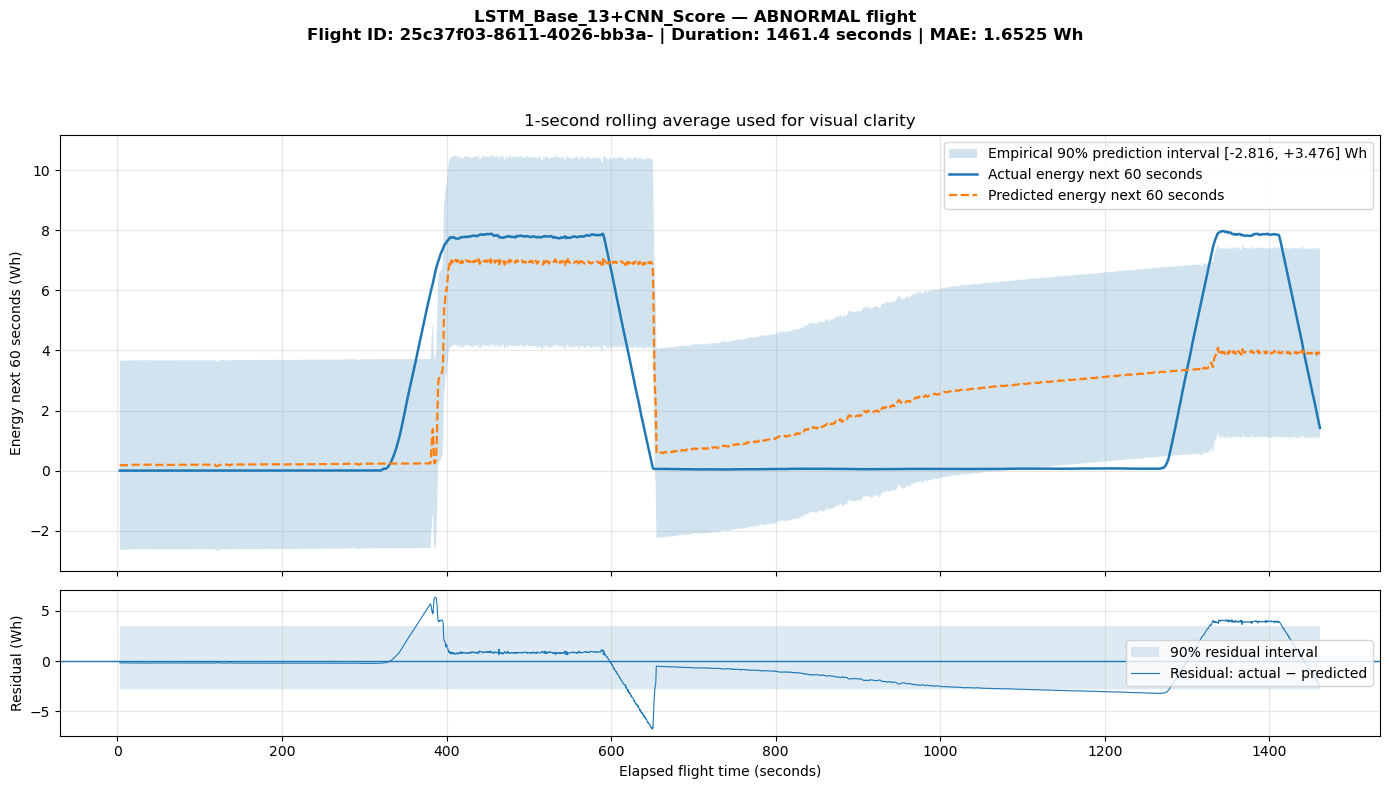

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy/plots/energy_prediction_LSTM_Base_13_CNN_Score_abnormal.png


,log_id,dataset_label,time_s,y_true,y_pred,sample_number,elapsed_s,actual_plot,predicted_plot
0,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,-1.179336,0.002063,0.184499,0,3.0,0.001948,0.184172
1,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,-1.179006,0.002005,0.184158,1,3.1,0.001929,0.184143
2,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,-1.178675,0.001948,0.184106,2,3.2,0.001915,0.184060
3,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,-1.178345,0.001890,0.184068,3,3.3,0.001905,0.183914
4,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,-1.178014,0.001833,0.184030,4,3.4,0.001897,0.183747
...,...,...,...,...,...,...,...,...,...
14580,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,3.639364,1.443346,3.931887,14580,1461.0,1.451082,3.905762
14581,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,3.639695,1.428383,3.927674,14581,1461.1,1.444030,3.907389
14582,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,3.640025,1.413419,3.921935,14582,1461.2,1.436860,3.909950
14583,25c37f03-8611-4026-bb3a-ae908b19fb71,abnormal,3.640356,1.401152,3.916314,14583,1461.3,1.429520,3.913495


In [35]:
plot_energy_prediction(
    run_name="LSTM_Base_13+CNN_Score",
    flight_label="abnormal",
)


Generating: XGBoost_Base_13 — normal


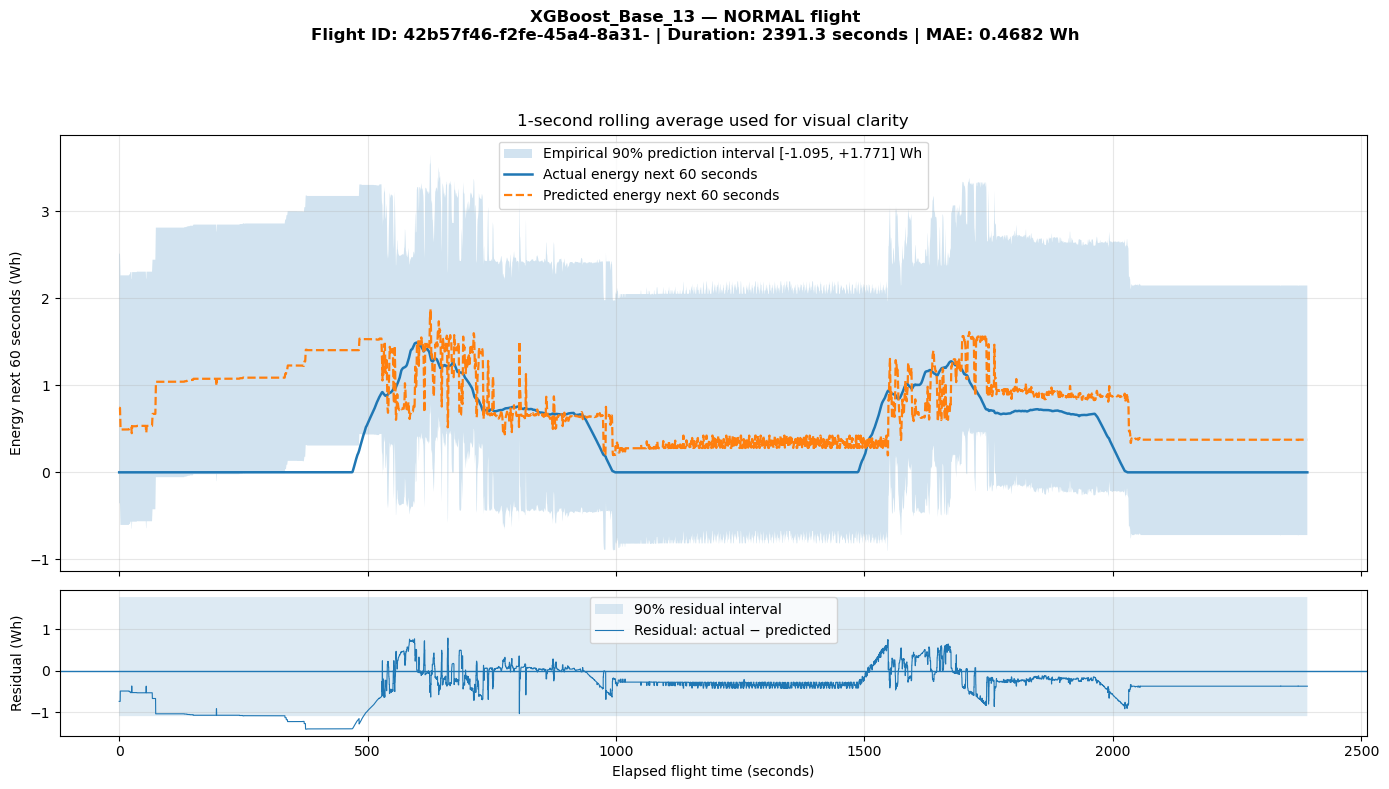

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy/plots/energy_prediction_XGBoost_Base_13_normal.png

Generating: XGBoost_Base_13 — abnormal


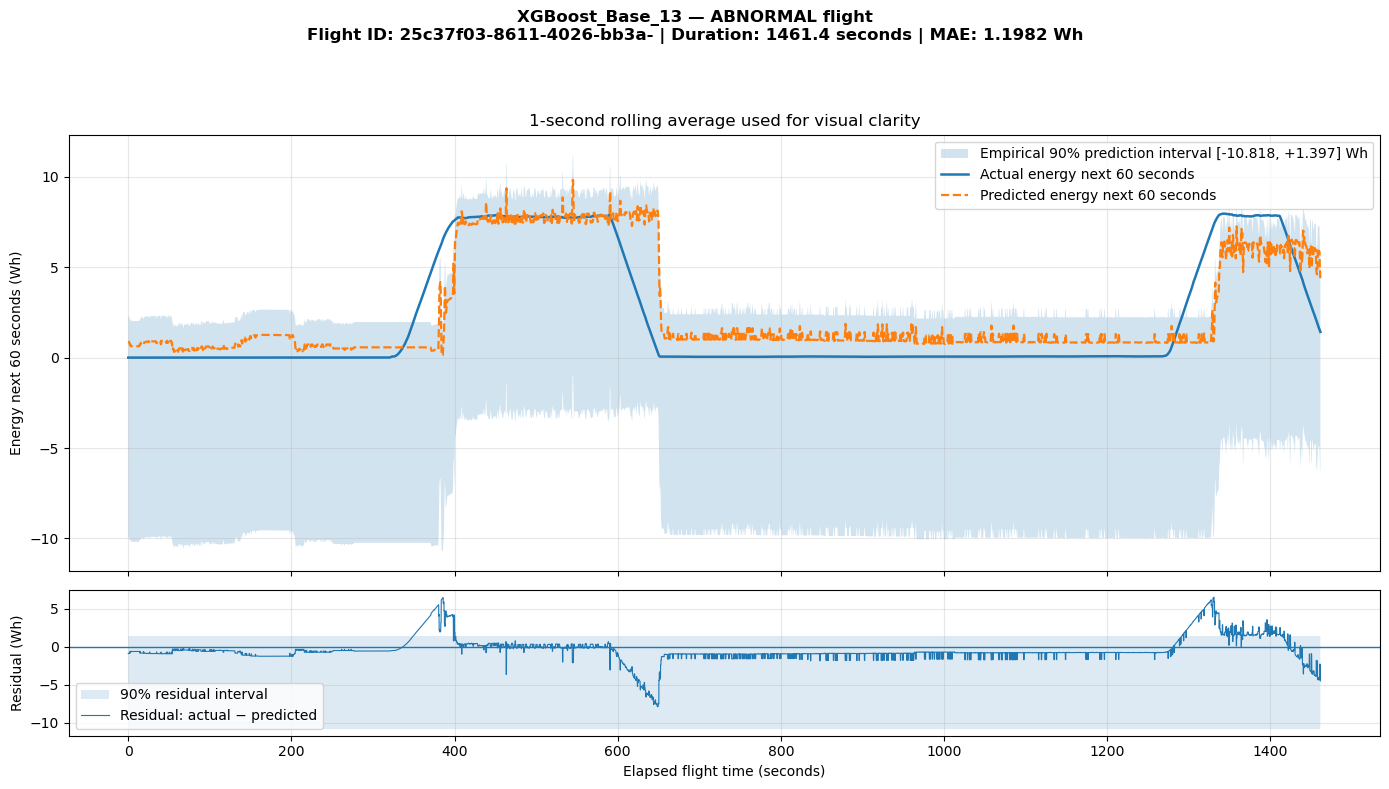

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy/plots/energy_prediction_XGBoost_Base_13_abnormal.png

Generating: XGBoost_Base_13+CNN_Score — normal


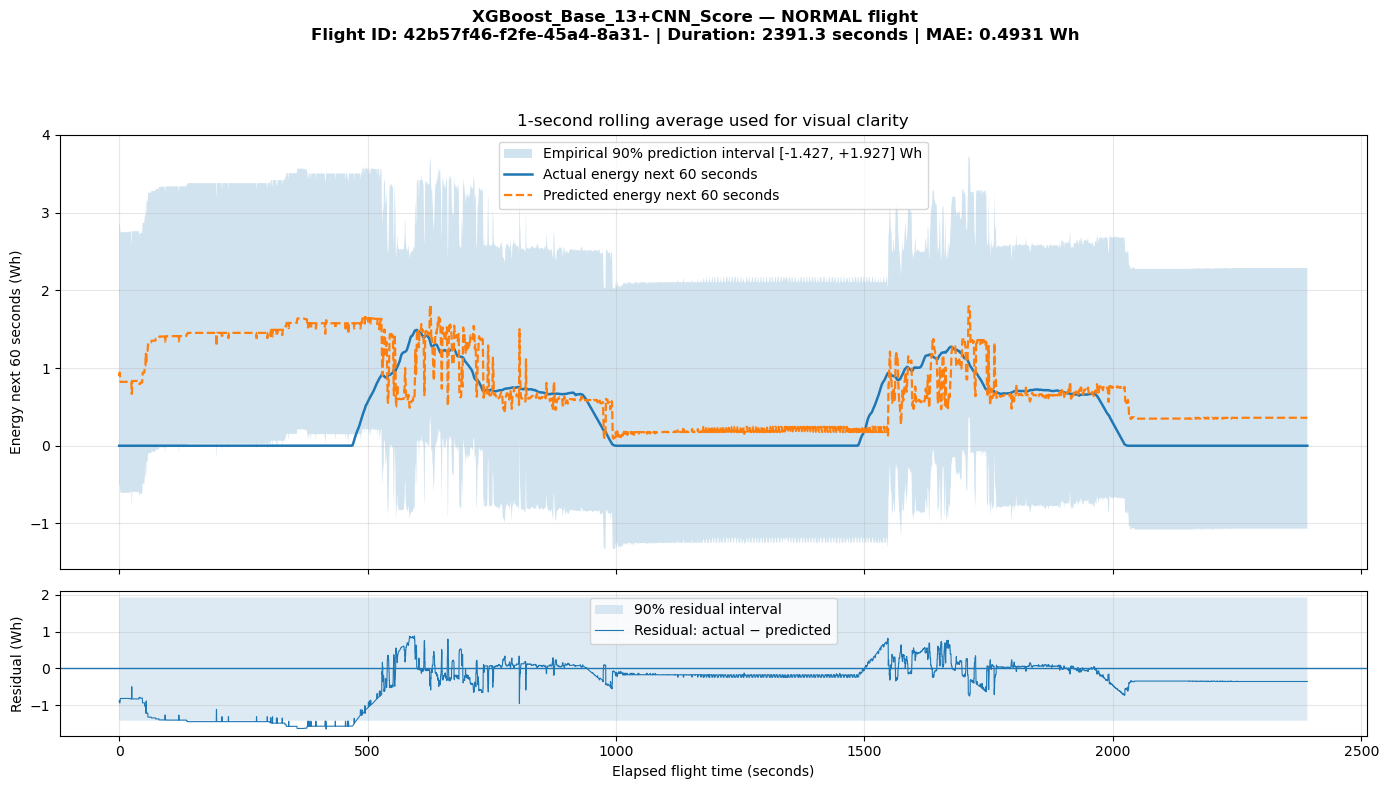

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy/plots/energy_prediction_XGBoost_Base_13_CNN_Score_normal.png

Generating: XGBoost_Base_13+CNN_Score — abnormal


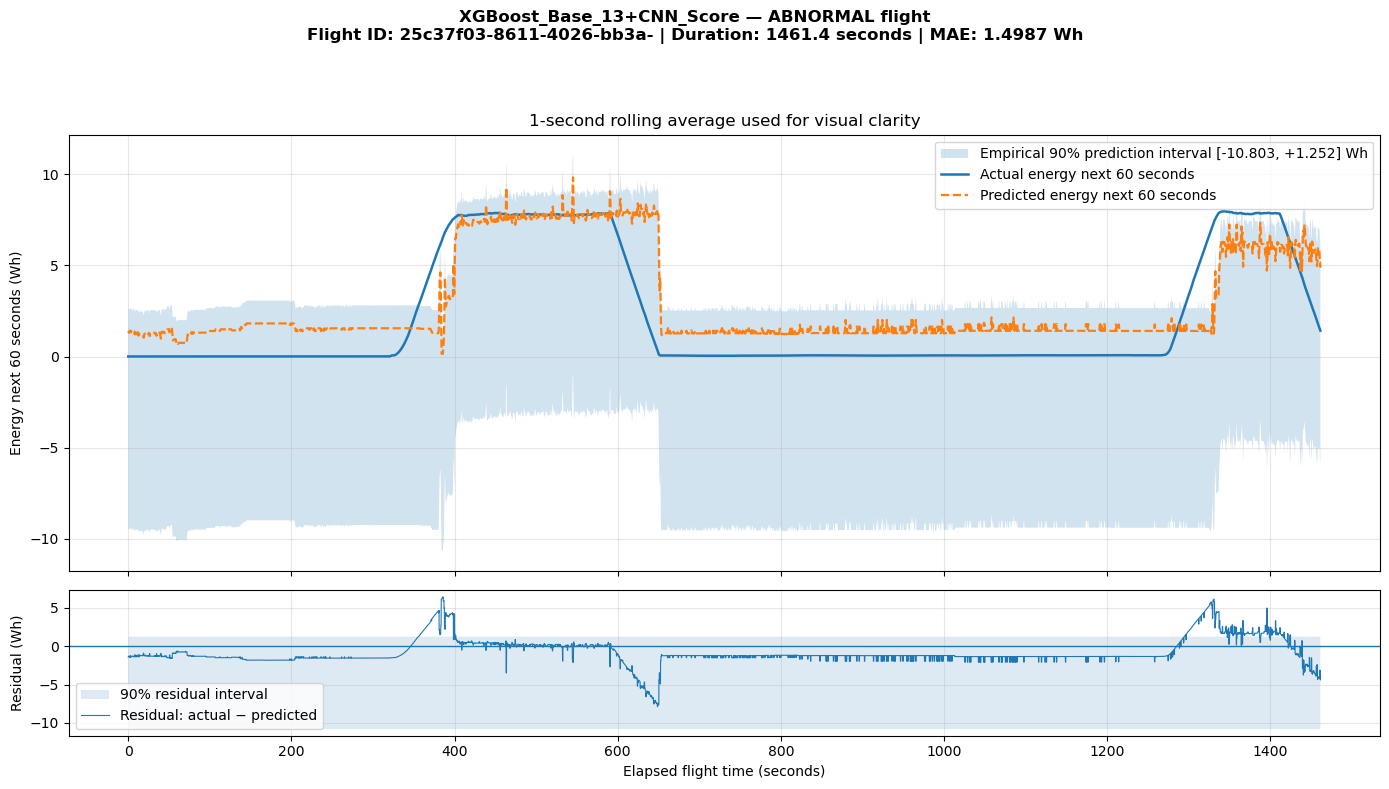

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy/plots/energy_prediction_XGBoost_Base_13_CNN_Score_abnormal.png

Generating: LSTM_Base_13 — normal


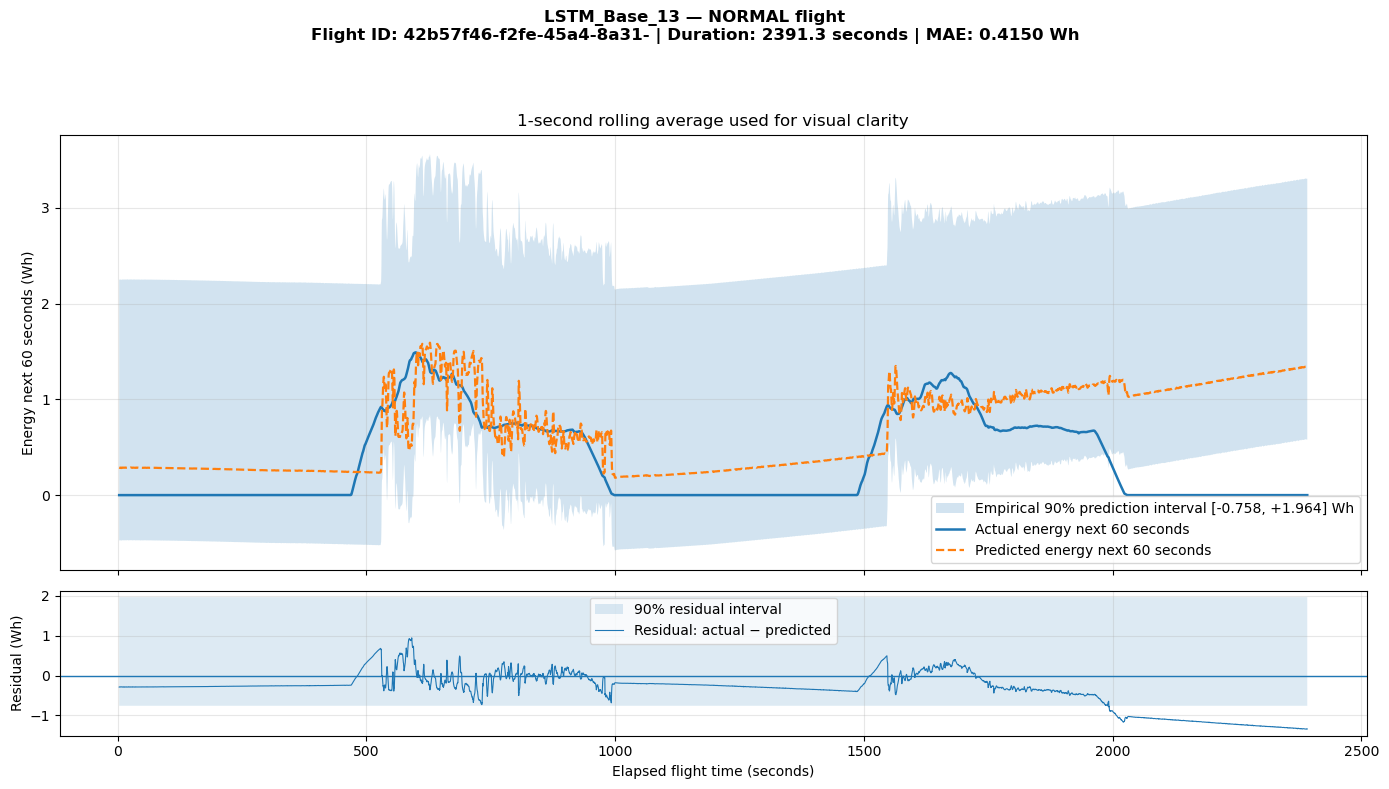

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy/plots/energy_prediction_LSTM_Base_13_normal.png

Generating: LSTM_Base_13 — abnormal


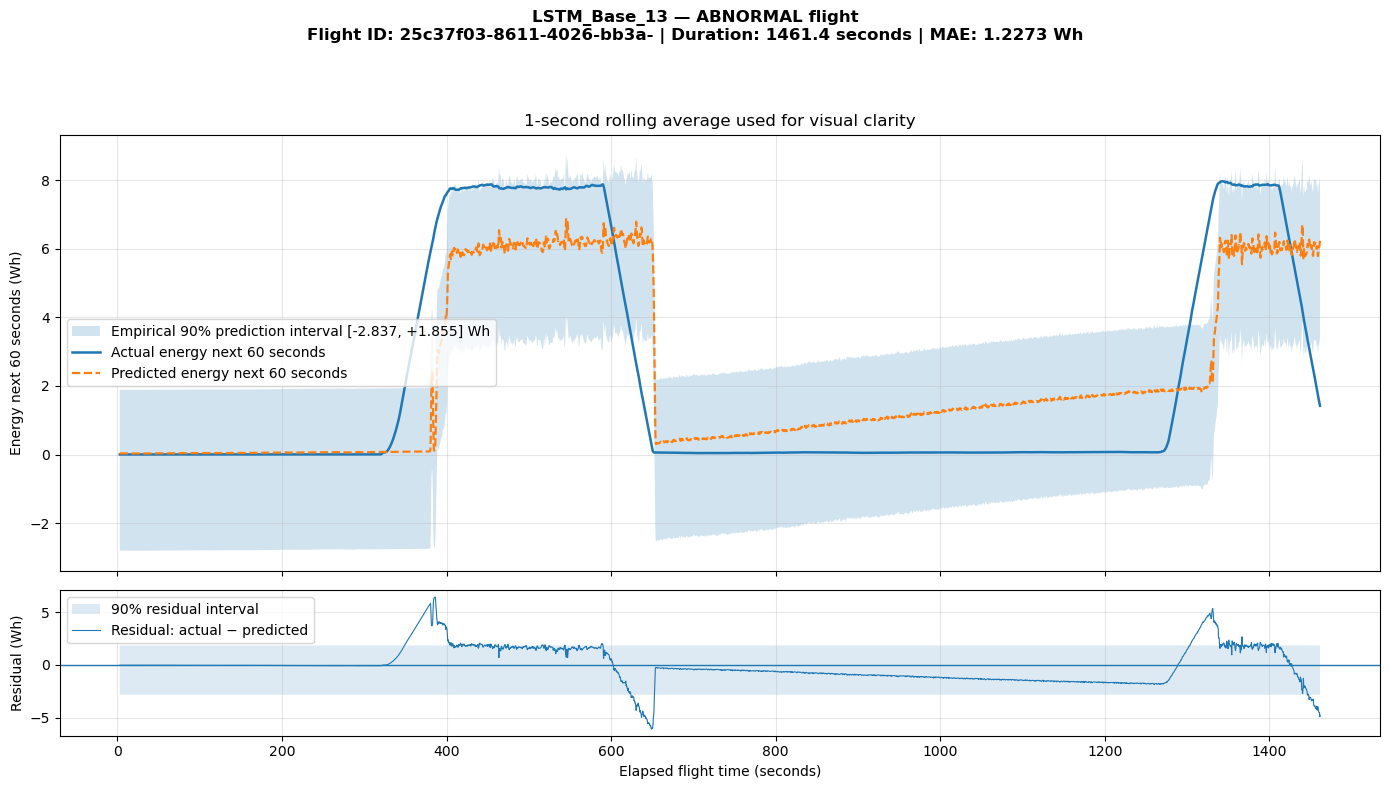

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy/plots/energy_prediction_LSTM_Base_13_abnormal.png

Generating: LSTM_Base_13+CNN_Score — normal


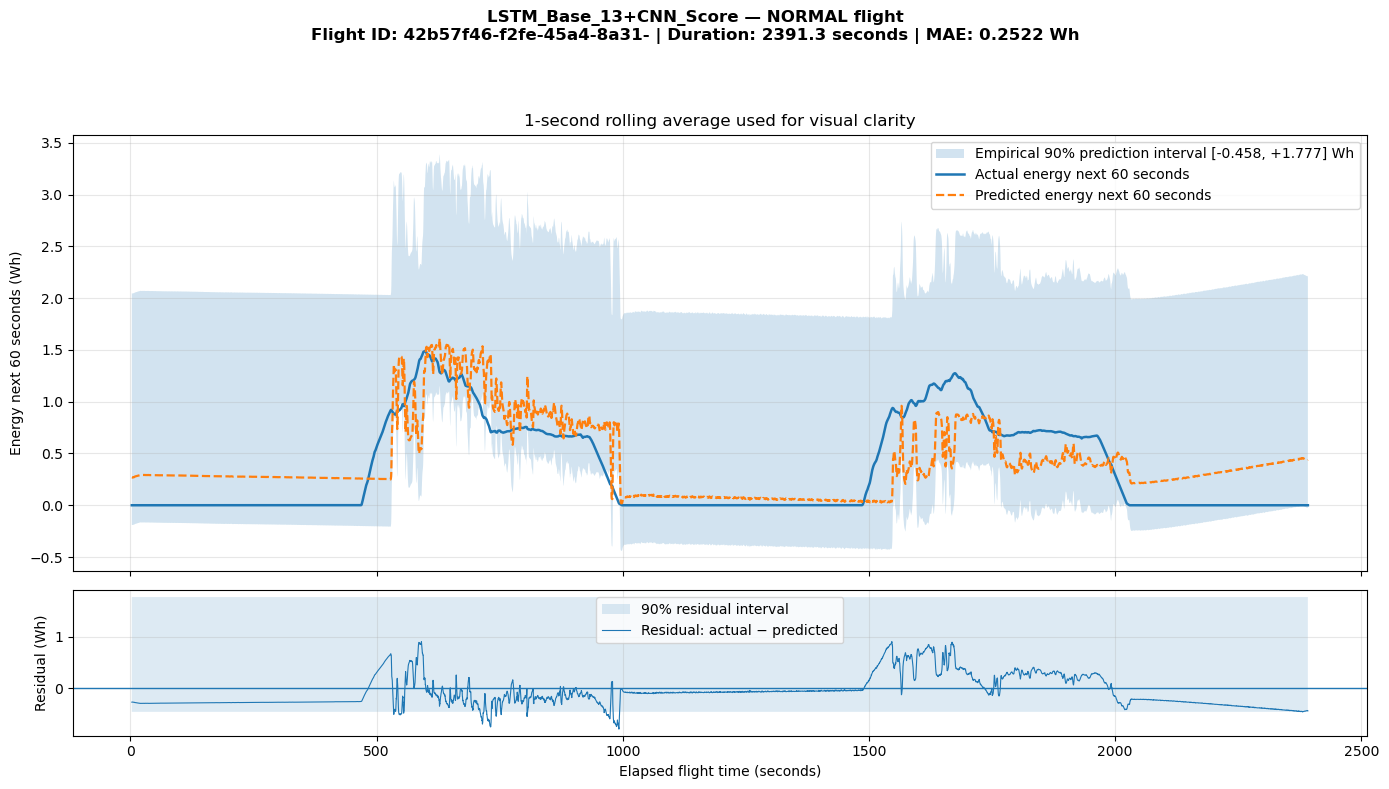

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy/plots/energy_prediction_LSTM_Base_13_CNN_Score_normal.png

Generating: LSTM_Base_13+CNN_Score — abnormal


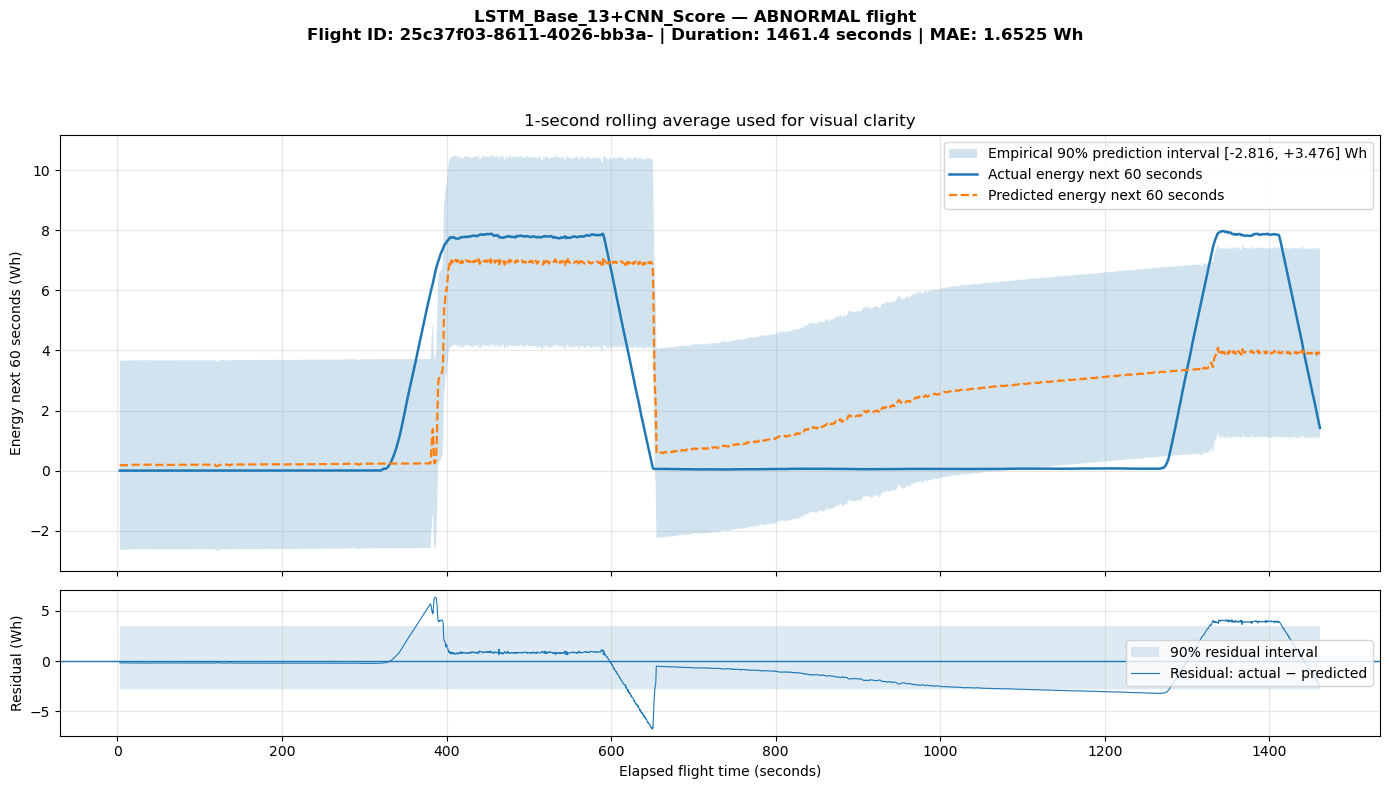

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/06_anomaly_aware_energy/plots/energy_prediction_LSTM_Base_13_CNN_Score_abnormal.png

All corrected energy-prediction plots generated.


In [36]:
RUNS_TO_PLOT = [
    "XGBoost_Base_13",
    "XGBoost_Base_13+CNN_Score",
    "LSTM_Base_13",
    "LSTM_Base_13+CNN_Score",
]

for run_name in RUNS_TO_PLOT:
    for label_name in ["normal", "abnormal"]:
        print(
            f"\nGenerating: {run_name} — {label_name}"
        )

        plot_energy_prediction(
            run_name=run_name,
            flight_label=label_name,
        )

print("\nAll corrected energy-prediction plots generated.")